[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_metcalfe_changes/BA_L2_metcalfe_changes.ipynb)

# BA_L2_metcalfe_changes: Metcalfe's Law in Levels and in Changes

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Bitcoin market value against transactions per day, monthly, November 2014 to October 2025: log levels with the fitted slope and the Metcalfe slope of 2, and monthly log changes with their fitted slope.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Data and method

Monthly means of Bitcoin's market value $M_t$ and transactions per day $n_t$, with the 11 days of recording error
(27 August to 6 September 2023) removed. The regression $\ln M_t = a + b\ln n_t + u_t$ is fitted in levels
(Newey–West standard errors, 12 lags) and in monthly changes, $\Delta\ln M_t$ on $\Delta\ln n_t$ (3 lags).
Metcalfe's law predicts $b = 2$.

**How to read the chart.** Left: both series trend upwards, so the cloud of levels is long and tilted. Right: in
changes the trends are removed and the cloud is almost round: the slope falls from 3.6 to 0.3.

In [5]:
from scipy import stats
import statsmodels.api as sm


def close_cal(sym, start, end=END):
    # closes on the asset's own calendar: crypto every day; S&P 500 and gold Monday-Friday, repeated closes removed
    s = daily(sym, end).loc[start:]
    if not sym.endswith('.CC'):
        s = s[s.index.dayofweek < 5]
        s = s[s.diff() != 0]
    return s


def log_returns(sym, start='2017-12-31', first='2018-01-01', end=END):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1}), from `first`
    return (100 * np.log(close_cal(sym, start, end)).diff()).dropna().loc[first:]

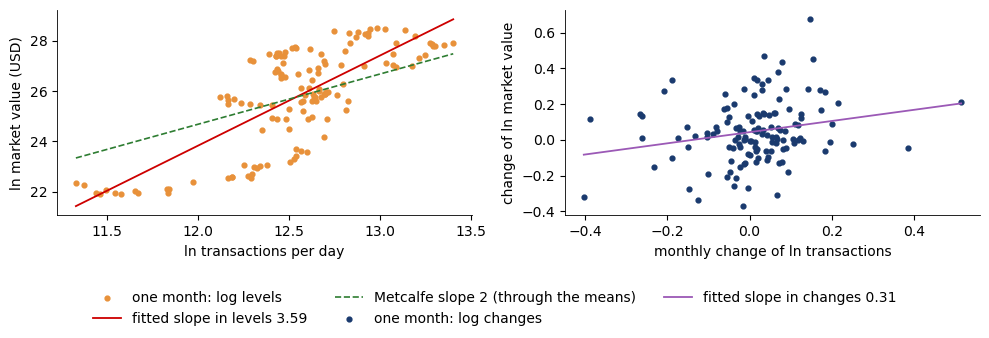

Levels: 132 months, b = 3.59 (SE 0.43), R2 = 0.58
Changes: 131 months, b = 0.31 (SE 0.15), R2 = 0.05
Standard deviation of the monthly changes: ln transactions 0.123, ln market value 0.174
Correlation of the monthly changes: 0.22


In [6]:
# Metcalfe's law: log levels against monthly log changes, Bitcoin, November 2014 - October 2025
tx_m = pd.to_numeric(onchain('transaction')['BTC'], errors='coerce')
mc_m = pd.to_numeric(onchain('Mktcap')['BTC'], errors='coerce')
mc_m.loc['2023-08-27':'2023-09-06'] = np.nan                      # recording error (Lecture 1)
mon = pd.DataFrame({'tx': tx_m, 'mc': mc_m}).dropna().resample('ME').mean().dropna()
ly, lx = np.log(mon['mc']), np.log(mon['tx'])
fit_l = sm.OLS(ly, sm.add_constant(lx)).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
dly, dlx = ly.diff().dropna(), lx.diff().dropna()
fit_d = sm.OLS(dly, sm.add_constant(dlx)).fit(cov_type='HAC', cov_kwds={'maxlags': 3})

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].scatter(lx, ly, color=BTC, s=12, label='one month: log levels')
xs = np.linspace(lx.min(), lx.max(), 50)
ax[0].plot(xs, fit_l.params.iloc[0] + fit_l.params.iloc[1] * xs, color=RED, lw=1.3, label=f'fitted slope in levels {fit_l.params.iloc[1]:.2f}')
ax[0].plot(xs, ly.mean() + 2 * (xs - lx.mean()), color=GREEN, ls='--', lw=1.2, label='Metcalfe slope 2 (through the means)')
ax[0].set_xlabel('ln transactions per day'); ax[0].set_ylabel('ln market value (USD)')
ax[1].scatter(dlx, dly, color=BLUE, s=12, label='one month: log changes')
xd = np.linspace(dlx.min(), dlx.max(), 50)
ax[1].plot(xd, fit_d.params.iloc[0] + fit_d.params.iloc[1] * xd, color=ETH, lw=1.3, label=f'fitted slope in changes {fit_d.params.iloc[1]:.2f}')
ax[1].set_xlabel('monthly change of ln transactions'); ax[1].set_ylabel('change of ln market value')
legend_below(fig, ncol=3, bottom=0.18)
save_fig(fig, 'ba_l2_metcalfe_changes')
print(f'Levels: {len(mon)} months, b = {fit_l.params.iloc[1]:.2f} (SE {fit_l.bse.iloc[1]:.2f}), R2 = {fit_l.rsquared:.2f}')
print(f'Changes: {len(dly)} months, b = {fit_d.params.iloc[1]:.2f} (SE {fit_d.bse.iloc[1]:.2f}), R2 = {fit_d.rsquared:.2f}')
print(f'Standard deviation of the monthly changes: ln transactions {dlx.std():.3f}, ln market value {dly.std():.3f}')
print(f'Correlation of the monthly changes: {np.corrcoef(dlx, dly)[0, 1]:.2f}')